**Computer vision input and outputs**

CNN as architecture


NHWC vs NCHW (colours channels last)


image: [None, 224, 224, 3] -> shape [3]

      [None, height, weight, colour_channel]

- input layer
- convulotional layer 'torch.nn.cc.Conv2d'
- hidden activation (non-linear)
- pooling layer
- output layer

**0. Libraries**

- 'torchvision' = base domain library
- 'torchvision.datasets' = get datasets and data loading tools
- 'torchvision.models' = get pretrained computer vision models
- 'torchvision.transforms' = functions for manipulating your vision data (images)
- 'torch.utils.data.Dataset'


In [55]:
import torch
from torch import nn

# import torchvision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# import matplotlib for visualization
import matplotlib.pyplot as plt

print(torch.__version__)
print(torchvision.__version__)

2.11.0+cu130
0.26.0+cu130


**1. Getting a dataset**

1998 - the "hello world!" of ML


In [56]:
# Setup the training data
train_data = datasets.FashionMNIST(
    root='data', # where to download data to ?
    train=True, # do we want the training dataset ?
    download=True,  # do we want to download ?
    transform=torchvision.transforms.ToTensor(),  # how do we want to transform the data
    target_transform=None # how do we want to transform the labels
)

test_data = datasets.FashionMNIST(
    root='data',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)



In [57]:
len(train_data), len(test_data)

(60000, 10000)

In [58]:
# See the first training example
image, label = train_data[0]
image, label


(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [59]:
image.shape

torch.Size([1, 28, 28])

In [60]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [61]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [62]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [63]:
print(f"Image shape: {image.shape} --> [color_channels, height, width]")
print(f"Image label: {class_names[label]}")

Image shape: torch.Size([1, 28, 28]) --> [color_channels, height, width]
Image label: Ankle boot


**1.2 Visualizing our data**

Image shape: torch.Size([1, 28, 28])


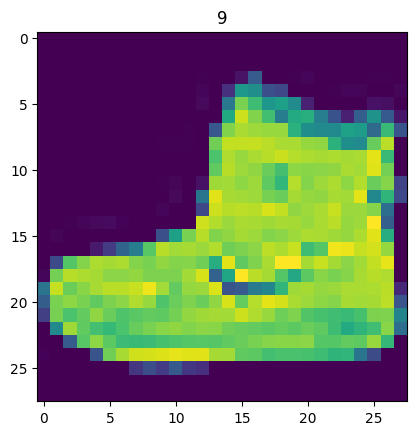

In [64]:
image, label = train_data[0]
print(f"Image shape: {image.shape}")
plt.imshow(image.squeeze())
plt.title(label);

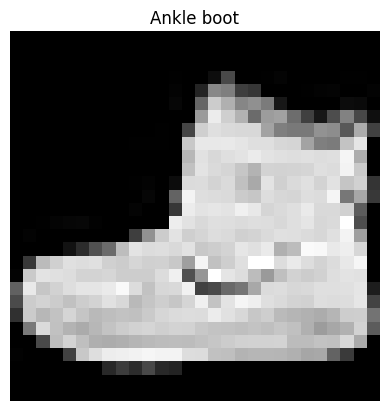

In [65]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label]);
plt.axis(False);

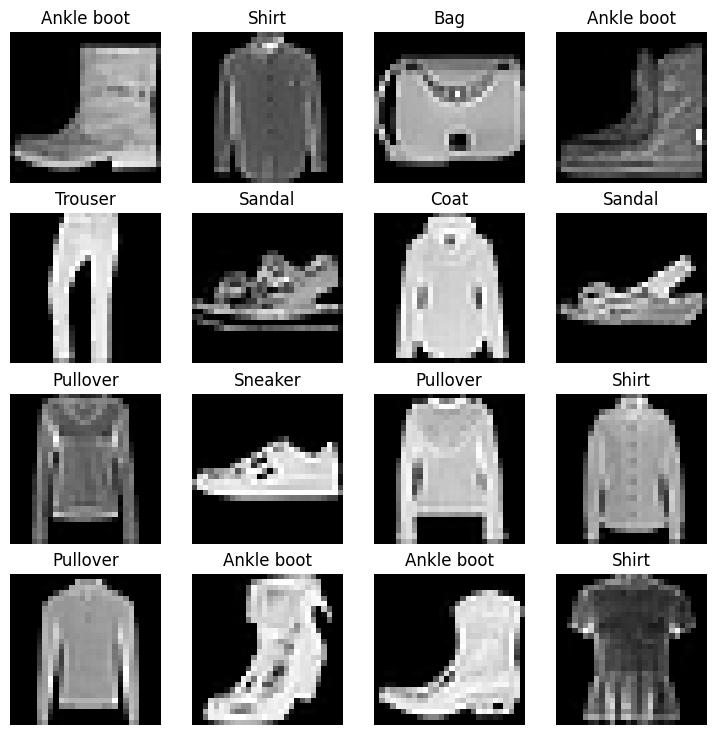

In [66]:
torch.manual_seed(42)
fig = plt.figure(figsize=(9,9))
rows, cols = 4,4
for i in range(1, rows*cols+1):
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  img, label = train_data[random_idx]
  fig.add_subplot(rows, cols,  i)
  plt.imshow(img.squeeze(), cmap="gray")
  plt.title(class_names[label])
  plt.axis(False);

In [67]:
train_data

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [68]:
test_data


Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()

2. Prepare DataLoader
- Prepare a Data Loader -> turn dataset into a Python iterable
- Turn our data into batches (mini batches)

-> more computationaly effective (memory storage) => so batch size 32


-> gives more chances to upgrade memory per epoch (one update per epoch for 60k vs one update per batch of 32 images)

In [69]:
from torch.utils.data import DataLoader # check the library

# Setup hyperparameters
BATCH_SIZE = 32

train_dataloader = DataLoader(
    dataset=train_data,   #60k
    batch_size=BATCH_SIZE,
    shuffle=True          # so that the order of batches is random
)

test_dataloader = DataLoader(
    dataset=test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7cffc0c8a210>,
 <torch.utils.data.dataloader.DataLoader at 0x7cffdcf5bbb0>)

In [70]:
# Let's see
print(f"Train Data : {train_dataloader}\nLength: {len(train_dataloader)} batches of {BATCH_SIZE} \nType: {type(train_dataloader)}")
print(" ")
print(f"Test Data : {test_dataloader}\nLength: {len(test_dataloader)} batches of {BATCH_SIZE} \nType: {type(test_dataloader)}")

Train Data : <torch.utils.data.dataloader.DataLoader object at 0x7cffc0c8a210>
Length: 1875 batches of 32 
Type: <class 'torch.utils.data.dataloader.DataLoader'>
 
Test Data : <torch.utils.data.dataloader.DataLoader object at 0x7cffdcf5bbb0>
Length: 313 batches of 32 
Type: <class 'torch.utils.data.dataloader.DataLoader'>


In [71]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))

train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image shape: torch.Size([1, 28, 28])
Image size: torch.Size([1, 28, 28])
Label: 6, label size: torch.Size([])


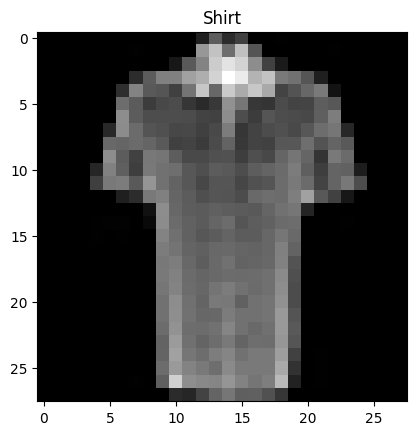

In [72]:
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
print(f"Image shape: {img.shape}")
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_names[label]);
print(f"Image size: {img.shape}")
print(f"Label: {label}, label size: {label.shape}")

3. Cretaing a baseline model

- simple model to improve on

In [73]:
# Create a flatten layer

flatten_model = nn.Flatten()

x = train_features_batch[0]
output = flatten_model(x)

print(f"Shape before flattening: {x.shape}")
print(f"Shape after flattening: {flatten_model(x).shape}")

Shape before flattening: torch.Size([1, 28, 28])
Shape after flattening: torch.Size([1, 784])


In [74]:
from torch import nn
class FashionMNISTModelV0(nn.Module):
  def __init__(self, input_shape: int,
               hidden_units: int,
               output_shape: int):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),       # what is this again ?
        nn.Linear(in_features=input_shape,
                  out_features=hidden_units),
        nn.Linear(in_features=hidden_units,
                  out_features=output_shape)
    )

  def forward(self, x):
    return self.layer_stack(x)



In [75]:
torch.manual_seed(42)
model_0 = FashionMNISTModelV0(
    input_shape = 784,    # 28 * 28
    hidden_units=10,      # how many units in the hidden layer
    output_shape=len(class_names) # one for every class
).to("cpu")

model_0

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [76]:
dummy_x = torch.rand([1, 1, 28, 28])
model_0(dummy_x).shape

torch.Size([1, 10])

Model_0 is the baseline model

Input and ouput shapes must line up

Dummy pass + shape check


In [77]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

**3.1 Setup loss + optimizer + evaluation metric**

- Loss function = 'nn.CrossEntropyLoss()'
- Optimizer = 'torch.optim.SGD()'
- Evaluation metric = accuracy

In [78]:
import requests
from pathlib import Path
# Download helper functions from Learn PyTorch

if Path ('helper_functions.py').is_file():
  print("helper_functions.py already exists")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)


helper_functions.py already exists


In [79]:
# Import accuracy metric
from helper_functions import accuracy_fn


In [80]:
# Setup loss funciton and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.1)

3.2 Creating a function to time our experiment
- Model's performance
- How fast it runs

In [81]:
# Time our experiment

from timeit import default_timer as timer

def print_train_time(start: float,
          end: float,
          device: torch.device=None):
  total_time = end - start
  print(f"Train time: {total_time:.3f} seconds")
  return total_time

In [82]:
start_time = timer()
end_time = timer()
print_train_time(start_time, end_time, device='cpu')

Train time: 0.000 seconds


6.0448999988693686e-05

**3.3 Creating a training loop and training on batches**
- Loop through epochs,
- Loop through training batches
- Loop through testing batches
- Calculate test loss per batch
- Print out
- Time it

In [83]:
import tqdm.auto as tqdm


In [84]:
# Import tqdm
from tqdm import tqdm

# Set the seed and start the timer
torch.manual_seed(42)
start_time = timer()

# Set the number of epochs kept small
epochs = 3

# Create a test loop
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch}")
  train_loss = 0

  for batch, (X, y) in enumerate(train_dataloader):     # loop inside the epoch, update happens once per batch
    model_0.train()
    # forward
    y_pred = model_0(X)
    #loss
    loss = loss_fn(y_pred, y)
    train_loss += loss
    #optimizer
    optimizer.zero_grad()
    #bakprop
    loss.backward()
    #learning step
    optimizer.step()

    if batch % 400 == 0:
      print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples.")

  train_loss /= len(train_dataloader)
  print(f"Train loss: {train_loss:.5f}")

  test_loss, test_acc = 0,0
  model_0.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      test_pred = model_0(X_test)
      test_loss += loss_fn(test_pred, y_test)
      test_acc += accuracy_fn(y_true=y_test,
                              y_pred=test_pred.argmax(dim=1))

    # Average test loss per batch
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)


  print(f"Train loss: {train_loss:.4f}")
  print(f"Test loss: {test_loss:.4f}")
  print(f"Test acc: {test_acc:.4f}")

  # Calculate the training time

train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=start_time,
                                            end=train_time_end_on_cpu,
                                            device=str(next(model_0.parameters())))






  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss: 0.59039


 33%|███▎      | 1/3 [00:09<00:19,  9.64s/it]

Train loss: 0.5904
Test loss: 0.5095
Test acc: 82.0387
Epoch: 1
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss: 0.47633


 67%|██████▋   | 2/3 [00:18<00:09,  9.04s/it]

Train loss: 0.4763
Test loss: 0.4799
Test acc: 83.1969
Epoch: 2
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss: 0.45503


100%|██████████| 3/3 [00:27<00:00,  9.20s/it]

Train loss: 0.4550
Test loss: 0.4766
Test acc: 83.4265
Train time: 27.594 seconds


In [85]:
next(model_0.parameters()).device

device(type='cpu')

**4. Make predictions and get Model 0 results**

In [86]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device: torch.device):
  loss, acc = 0,0
  model.eval()
  with torch.inference_mode():
    for X, y in data_loader:

      y_pred = model(X)
      loss += loss_fn(y_pred, y)
      acc += accuracy_fn(y_true=y,
                        y_pred=y_pred.argmax(dim=1))   #skip the softmax step by just taking the position

    loss /= len(data_loader)
    acc /= len(data_loader)

    return {"model_name": model.__class__.__name__,
            "model_loss": loss.item(),
            "model_acc": acc}

model_0_results = eval_model(model=model_0,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device="cpu")
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': 83.42651757188499}

In [87]:
# Setup device agnostic code
!nvidia-smi

Tue Oct  6 15:30:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P0             28W /   70W |     161MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [88]:
torch.cuda.is_available()

True

In [89]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

**6. Building a model using non-linearity**

In [90]:
class FashionMNISTModelV1(nn.Module):
  def __init__(self,
               input_shape: int,
               hidden_units: int,
               output_shape: int,):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape,      # again, what is this ?
                  out_features=hidden_units),   # same for this one
        nn.ReLU(),
        nn.Linear(in_features=hidden_units,
                  out_features=output_shape),
        nn.ReLU()
    )
  def forward(self, x: torch.Tensor):
    return self.layer_stack(x)

In [91]:
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape=784,
                              hidden_units=10,
                              output_shape=len(class_names)).to(device) # send to GPU if available
next(model_1.parameters()).device

device(type='cuda', index=0)

In [92]:
# loss & otpimizer & evaluation metrics
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.1)


Training and testing/evaluation loop
- training loop - train_step()
- testing loop - test_step()


In [93]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device=device):

  train_loss, train_acc = 0,0
  model.train()

  for batch, (X, y) in enumerate(train_dataloader):     # loop inside the epoch, update happens once per batch
    # data to device
    X, y = X.to(device), y.to(device)

    # forward
    y_pred = model(X)

    #loss
    loss = loss_fn(y_pred, y)
    train_loss += loss
    train_acc += accuracy_fn(y_true=y,
                             y_pred=y_pred.argmax(dim=1))

    #optimizer
    optimizer.zero_grad()

    #bakprop
    loss.backward()

    #learning step
    optimizer.step()

  # outside of the loop
  train_loss /= len(train_dataloader)
  train_acc /= len(train_dataloader)

  return {"train_loss": train_loss.item(),
          "train_acc": train_acc}


In [94]:
def test_step(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device = device):

  test_loss, test_acc = 0,0

  # model in eval
  model.eval()

  # turn on inference mode
  with torch.inference_mode():
    for X, y in data_loader:
      X, y = X.to(device), y.to(device)
      test_pred = model(X)
      test_loss += loss_fn(test_pred, y)
      test_acc += accuracy_fn(y_true=y,
                              y_pred=test_pred.argmax(dim=1))

    # adjust metric and print out
    test_loss /= len(data_loader)
    test_acc /= len(data_loader)

print(f"test_loss: {test_loss.item():.4f}, test_acc: {test_acc:.2f}%")

test_loss: 0.4766, test_acc: 83.43%


Created two functions :
- test
- train
Re-use for the training loop


In [95]:
torch.manual_seed(42)
# mesure time
from timeit import default_timer as timer
train_time_start_on_gpu = timer()
epochs = 3

# Create a loop
for epoch in tqdm(range(epochs)):

# Optimizer loop in a few lines imported from above
  print(f"Epoch: {epoch}")
  train_step(model_1,
             data_loader=train_dataloader,
             loss_fn=loss_fn,
             optimizer=optimizer,
             accuracy_fn=accuracy_fn,
             device=device)

  test_step(model_1,
            data_loader=test_dataloader,
            loss_fn=loss_fn,
            accuracy_fn=accuracy_fn,
            device=device)

train_time_end_on_gpu = timer()
total_train_time_model_1 = print_train_time(start=train_time_start_on_gpu,
                                            end=train_time_end_on_gpu,
                                            device=str(next(model_1.parameters()).device))


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0


 33%|███▎      | 1/3 [00:11<00:23, 11.85s/it]

Epoch: 1


 67%|██████▋   | 2/3 [00:22<00:10, 10.93s/it]

Epoch: 2


100%|██████████| 3/3 [00:32<00:00, 10.75s/it]

Train time: 32.244 seconds


In [96]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': 83.42651757188499}

In [97]:
total_train_time_model_0

27.59370129299998

In [98]:
model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6850008964538574,
 'model_acc': 75.01996805111821}

In [99]:
# Get model_1 results dictionary

def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device: torch.device):
  loss, acc = 0,0
  model.eval()
  with torch.inference_mode():
    for X, y in data_loader:

      # device agnostic
      X, y = X.to(device), y.to(device)

      y_pred = model(X)
      loss += loss_fn(y_pred, y)
      acc += accuracy_fn(y_true=y,
                        y_pred=y_pred.argmax(dim=1))   #skip the softmax step by just taking the position

    loss /= len(data_loader)
    acc /= len(data_loader)

    return {"model_name": model.__class__.__name__,
            "model_loss": loss.item(),
            "model_acc": acc}

model_1_results = eval_model(model=model_1,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6850008964538574,
 'model_acc': 75.01996805111821}

In [100]:
total_train_time_model_1

32.24396657099999

Faster on CPU acutally

Dataset too small to compound

**Model 2 : building a Convolutional Neural Network - CNN**

CNN architecture research updates quicky (popular architectures search)

https://poloclub.github.io/cnn-explainer/$0


In [101]:
class FashionMNISTModelV2(nn.Module):
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
    super().__init__()
    self.conv_block_1=nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,

                  # hyperparameters for Conv2d
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )

    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*7*7,
                  out_features=output_shape)
    )

  def forward(self, x: torch.Tensor):
    x = self.conv_block_1(x)
    # print(x.shape)
    x = self.conv_block_2(x)
    # print(x.shape)
    x = self.classifier(x)
    # print(x.shape)
    return x



In [102]:
torch.manual_seed(42)
model_2=FashionMNISTModelV2(input_shape=1,
                            hidden_units=10,
                            output_shape=len(class_names)).to(device)
model_2

FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

**7.1 Stepping through Conv2d**

- Input layer
- Conv2d layer
- ReLU activation layer
- Pooling layer
- Output layer



In [103]:
from numpy import size
torch.manual_seed(42)

# Create a batch of images
images = torch.rand(size=(32, 3, 64, 64))
test_image = images[0]
print(f"Image batch shape:{images.shape}")
print(f"Single image shape:{test_image.shape}")
print(f"Test image:{test_image}")

Image batch shape:torch.Size([32, 3, 64, 64])
Single image shape:torch.Size([3, 64, 64])
Test image:tensor([[[0.8823, 0.9150, 0.3829,  ..., 0.1587, 0.6542, 0.3278],
         [0.6532, 0.3958, 0.9147,  ..., 0.2083, 0.3289, 0.1054],
         [0.9192, 0.4008, 0.9302,  ..., 0.5535, 0.4117, 0.3510],
         ...,
         [0.1457, 0.1499, 0.3298,  ..., 0.9624, 0.6400, 0.7409],
         [0.1709, 0.5797, 0.6340,  ..., 0.6885, 0.2405, 0.5956],
         [0.9199, 0.1247, 0.3573,  ..., 0.6752, 0.2058, 0.5027]],

        [[0.1458, 0.9024, 0.9217,  ..., 0.1868, 0.6352, 0.8431],
         [0.9549, 0.4435, 0.6924,  ..., 0.1168, 0.7160, 0.5462],
         [0.1616, 0.1054, 0.8614,  ..., 0.4531, 0.4736, 0.9448],
         ...,
         [0.4309, 0.3986, 0.1907,  ..., 0.9444, 0.2848, 0.3776],
         [0.7948, 0.6855, 0.1009,  ..., 0.6147, 0.7747, 0.2323],
         [0.5840, 0.9795, 0.3277,  ..., 0.3549, 0.1263, 0.1280]],

        [[0.5027, 0.4195, 0.8893,  ..., 0.3084, 0.1567, 0.7860],
         [0.7310, 0.930

In [104]:

conv_layer = nn.Conv2d(in_channels=3,     # nb of colour channels
                       out_channels=10,   #
                       kernel_size=3,
                       stride=1,
                       padding=1
                       )                  # compressing the representation basically

conv_output = conv_layer(test_image)
conv_output

# try plaing around with the hyperparameters
print(f"conv_output.shape:{conv_output.shape}")

# intelligence is compression
print(conv_output[0])


conv_output.shape:torch.Size([10, 64, 64])
tensor([[-0.3337, -0.3328, -0.5084,  ..., -0.2369, -0.2811, -0.3181],
        [-0.3304, -0.4432, -0.4266,  ..., -0.4029, -0.2580, -0.3959],
        [-0.0560, -0.5172, -0.6280,  ..., -0.2697, -0.3392, -0.3886],
        ...,
        [-0.0273, -0.3849, -0.4654,  ..., -0.4689, -0.4657, -0.2296],
        [-0.1974, -0.5404, -0.1720,  ..., -0.5228, -0.5067, -0.2956],
        [-0.2509, -0.5954, -0.6721,  ..., -0.5358, -0.3137, -0.2235]],
       grad_fn=<SelectBackward0>)


In [105]:
print(f"Test image shape: {test_image.shape}")

# Create a sample nn.MaxPool2d layer
max_pool_layer = nn.MaxPool2d(kernel_size=2)

# Pass data through just the conv_layer
test_image_through_conv_layer = conv_layer(test_image)
print(f"Test_image_through_conv_layer.shape:{test_image_through_conv_layer.shape}")

# Pass data through the max ppool layer
test_image_through_conv_and_max_pool = max_pool_layer(test_image_through_conv_layer)
print(f"Test_image_through_conv_and_max_pool.shape:{test_image_through_conv_and_max_pool.shape}")


Test image shape: torch.Size([3, 64, 64])
Test_image_through_conv_layer.shape:torch.Size([10, 64, 64])
Test_image_through_conv_and_max_pool.shape:torch.Size([10, 32, 32])


In [106]:
torch.manual_seed(42)

# Create a 4 dimensional tensor
random_tensor = torch.randn(size=(1,1,2,2))
print(f"Random tensor:{random_tensor}\n")
print(f"Random tensor shape: {random_tensor.shape}")
print(" ")

# Create a max pool layer
max_pool_layer = nn.MaxPool2d(kernel_size=2)

# Pass the random tesor through the max pool layer
max_pool_tensor = max_pool_layer(random_tensor)
print(f"Max pool tensor:{max_pool_tensor}")
print(f"Max pool tensor shape: {max_pool_tensor.shape}")
print(" ")

random_tensor

# reduction of the size of the tensor from (2,2) to a (1,1)

Random tensor:tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])

Random tensor shape: torch.Size([1, 1, 2, 2])
 
Max pool tensor:tensor([[[[0.3367]]]])
Max pool tensor shape: torch.Size([1, 1, 1, 1])
 


tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])

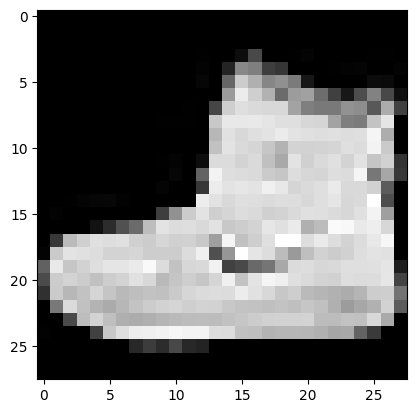

In [107]:
plt.imshow(image.squeeze(dim=0), cmap="gray")

In [108]:
rand_image_tensor = torch.randn(size=(1,28,28))
rand_image_tensor.shape

torch.Size([1, 28, 28])

In [109]:
model_2(rand_image_tensor.unsqueeze(0).to(device))

tensor([[ 0.0424, -0.0839,  0.0839, -0.0463,  0.0053,  0.0437,  0.0025,  0.0108,
         -0.0158, -0.0177]], device='cuda:0', grad_fn=<AddmmBackward0>)

**7.3 Setup a loss function and optimizer**

In [110]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_2.parameters(),
                            lr=0.1)

**7.4 Training and testing model_2**

In [111]:
torch.manual_seed(42)

from timeit import default_timer as timer
train_time_start_model_2 = timer()

epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch}")
  train_step(model=model_2,
             data_loader=train_dataloader,
             loss_fn=loss_fn,
             optimizer=optimizer,
             accuracy_fn=accuracy_fn,
             device=device)
  test_step(model=model_2,
            data_loader=test_dataloader,
            loss_fn=loss_fn,
            accuracy_fn=accuracy_fn,
            device=device)

train_time_end_model_2 = timer()

train_time_end_model_2 = timer()
total_train_time_model_2 = print_train_time(start=train_time_start_model_2,
                                            end=train_time_end_model_2,
                                            device=device)


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0


 33%|███▎      | 1/3 [00:12<00:24, 12.11s/it]

Epoch: 1


 67%|██████▋   | 2/3 [00:24<00:12, 12.04s/it]

Epoch: 2


100%|██████████| 3/3 [00:36<00:00, 12.02s/it]

Train time: 36.061 seconds


In [112]:
model_2_results = eval_model(model=model_2,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32436317205429077,
 'model_acc': 88.03913738019169}

In [113]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': 83.42651757188499}

The CNN beats the baseline model but let's compare

In [114]:
import pandas as pd
compare_results = pd.DataFrame(data=[model_0_results,
                                     model_1_results,
                                     model_2_results])
compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,83.426518
1,FashionMNISTModelV1,0.685001,75.019968
2,FashionMNISTModelV2,0.324363,88.039137


In [115]:
# add training time to comparison results
compare_results["training_time"] = [f"{total_train_time_model_0}",
                                    f"{total_train_time_model_1}",
                                    f"{total_train_time_model_2}"]
compare_results


,model_name,model_loss,model_acc,training_time
0,FashionMNISTModelV0,0.476639,83.426518,27.59370129299998
1,FashionMNISTModelV1,0.685001,75.019968,32.24396657099999
2,FashionMNISTModelV2,0.324363,88.039137,36.06146479200004


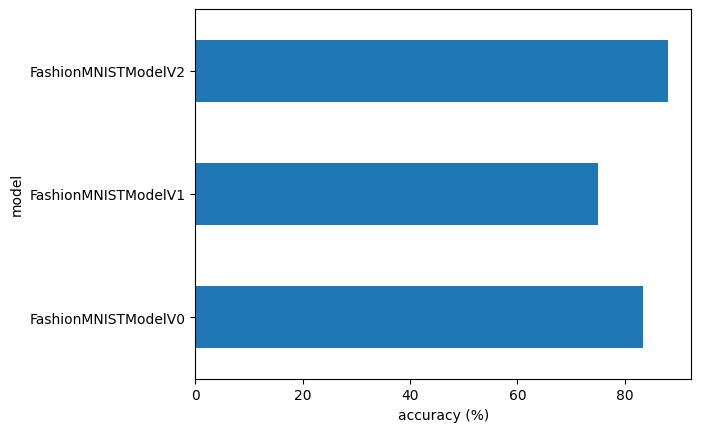

In [116]:
# visualize our model results
compare_results.set_index("model_name")["model_acc"].plot(kind="barh") # "bar" for vertical
plt.xlabel("accuracy (%)")
plt.ylabel("model");

9. Evaluate random predictions with best model

In [117]:
def make_predictions(model: torch.nn.Module,
                     data: list,
                     device: torch.device=device):
  pred_probs = []
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for sample in data:
      sample = torch.unsqueeze(sample, dim=0).to(device) # prepapre the sample add a batch dimension and pass to target device
      pred_logit = model(sample)                        # forward pass
      pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)  # get prediction probability
      pred_probs.append(pred_prob.cpu())                # get pred_prob off the GPU
  return torch.stack(pred_probs)                        # stack to turn list to a tensor

In [118]:
import random
random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
  test_samples.append(sample)
  test_labels.append(label)

  # view the first sample shape
test_samples[0].shape



torch.Size([1, 28, 28])

In [119]:
# make prediction on this random set of data

pred_probs = make_predictions(model=model_2,
                             data=test_samples)
pred_probs[:2]

tensor([[2.9617e-08, 2.3289e-09, 1.2640e-08, 6.0079e-09, 2.0514e-09, 9.9996e-01,
         4.6106e-09, 1.4972e-05, 1.6909e-05, 5.2658e-06],
        [6.2354e-02, 4.4882e-01, 2.3807e-03, 1.6541e-01, 9.0030e-02, 1.9393e-04,
         2.3008e-01, 4.2238e-04, 9.6489e-05, 2.0956e-04]])

In [120]:
# convert predictions to labels
pred_classes = pred_probs.argmax(dim=1)
pred_classes

tensor([5, 1, 7, 4, 3, 0, 4, 7, 1])

In [121]:
test_labels

[5, 1, 7, 4, 3, 0, 4, 7, 1]

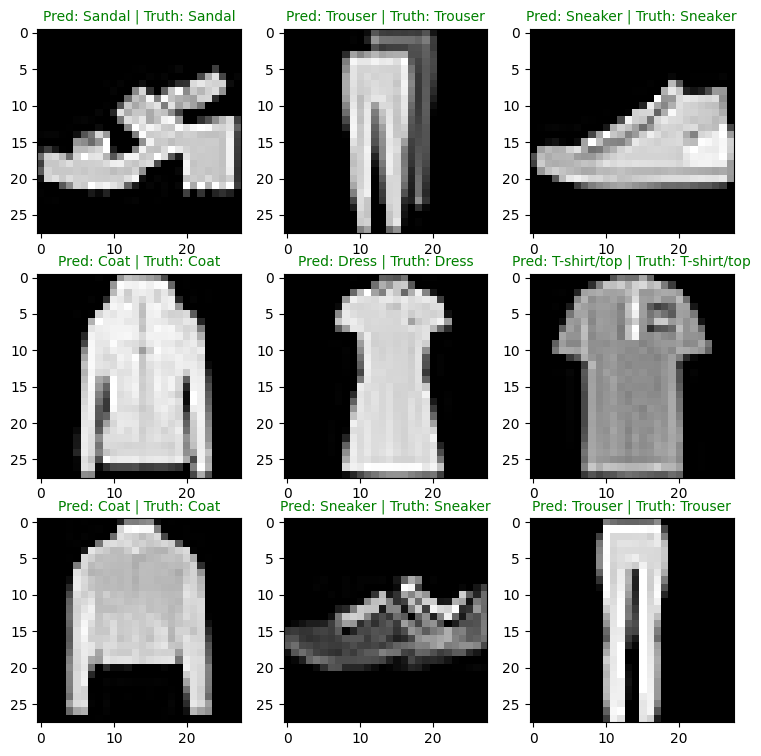

In [122]:
# Plot predictions
plt.figure(figsize=(9,9))
nrows=3
ncols=3
for i, sample in enumerate(test_samples):
  plt.subplot(nrows, ncols, i+1)
  plt.imshow(sample.squeeze(), cmap="gray")

  pred_label = class_names[pred_classes[i]]
  truth_label = class_names[test_labels[i]]
  title_text = f"Pred: {pred_label} | Truth: {truth_label}"

  if pred_label == truth_label:
    plt.title(title_text, fontsize=10, c="green")
  else:
    plt.title(title_text, fontsize=10, c="red")
    plt.axis("off")





**More classification and evaluation metrics**

A **confusion matrix** is a fantatic way of evaluating your classification

1. Make predictions with our trained model on the test dataset
2. Make confusion matrix
3. Plot the confusion matrix

In [123]:
import mlxtend
from tqdm.auto import tqdm

y_preds = []
model_2.eval()
with torch.inference_mode():
  for X, y in tqdm(test_dataloader, desc="Making predictions ..."):
    X, y = X.to(device), y.to(device)
    y_logit = model_2(X)
    y_pred = torch.softmax(y_logit.squeeze(), dim=0).argmax(dim=1)
    y_preds.append(y_pred.cpu())

y_preds = torch.cat(y_preds) # concatenate list of predictions
y_preds[:10]




Making predictions ...:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])

In [124]:
try:
  import torchmetrics, mlxtendprint
  print(f"torchmetrics version: {torchmetrics.__version__}")

except:
  !pip install torchmetrics
  import torchmetrics, mlxtend
  print("done")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 50.4 MB/s eta 0:00:00
done


In [125]:
import mlxtend
print(mlxtend.__version__)

0.23.4


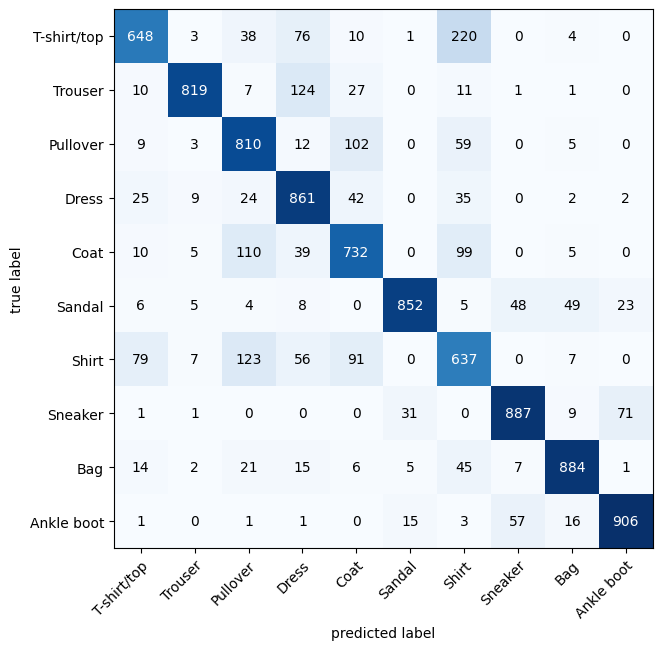

In [127]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

confmat = ConfusionMatrix(task="multiclass", num_classes=len(class_names))
confmat_tensor = confmat(preds=y_preds,
                         target=test_data.targets)

fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=class_names,
    figsize=(10,7),
)


In [128]:
confmat_tensor

tensor([[648,   3,  38,  76,  10,   1, 220,   0,   4,   0],
        [ 10, 819,   7, 124,  27,   0,  11,   1,   1,   0],
        [  9,   3, 810,  12, 102,   0,  59,   0,   5,   0],
        [ 25,   9,  24, 861,  42,   0,  35,   0,   2,   2],
        [ 10,   5, 110,  39, 732,   0,  99,   0,   5,   0],
        [  6,   5,   4,   8,   0, 852,   5,  48,  49,  23],
        [ 79,   7, 123,  56,  91,   0, 637,   0,   7,   0],
        [  1,   1,   0,   0,   0,  31,   0, 887,   9,  71],
        [ 14,   2,  21,  15,   6,   5,  45,   7, 884,   1],
        [  1,   0,   1,   1,   0,  15,   3,  57,  16, 906]])

**11. Save and load best performing model**

In [129]:
from pathlib import Path

# Create model directory path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,
                 exist_ok=True)

# Create model save
MODEL_NAME = "03_pytorhc_computer_vision_model_2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

MODEL_SAVE_PATH

# Save model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_2.state_dict(),
           f=MODEL_SAVE_PATH)



Saving model to: models/03_pytorhc_computer_vision_model_2.pth


In [130]:
# Create a new instance
torch.manual_seed(42)

loaded_model_2 = FashionMNISTModelV2(input_shape=1,
                                     hidden_units=10,
                                     output_shape=len(class_names))
loaded_model_2.load_state_dict(torch.load(f=MODEL_SAVE_PATH))
loaded_model_2.to(device)


FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [131]:
# Evaluate the model

model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32436317205429077,
 'model_acc': 88.03913738019169}

In [132]:
torch.manual_seed(42)
loaded_model_2_results = eval_model(model=loaded_model_2,
                                    data_loader=test_dataloader,
                                    loss_fn=loss_fn,
                                    accuracy_fn=accuracy_fn,
                                    device=device)
loaded_model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32436317205429077,
 'model_acc': 88.03913738019169}

In [133]:
# check if model resultats are to close to each other
torch.isclose(torch.tensor(model_2_results["model_loss"]),
              torch.tensor(loaded_model_2_results["model_loss"]),
              atol=1e-02)

tensor(True)

Short Rashka detour "https://sebastianraschka.com/teaching/pytorch-1h/"

- auto grad library
- extends NumPy
- deep learning library with pre set building blocks

**PyTorch Library**
Scalar = zero dimension (1) vs Tensor = one dimension (3,1) vs Matrix = two dimensions (2,2)

ex : ("1") ("1,1,1") ("1,1,1,1")

If Tensor created with integers = 64 bits
If Tensor created with float = 32 bits
tensor.dtype()

Change the precision with 'tensor.to(torch.float32)'

Verify the shape of the tensor with 'tensor.shape' and 'tensor.reshape(X,Y)' or 'tensor.T' for flipping it

**Seeing models as computational graphs - PyTorch dfferentiation engine**

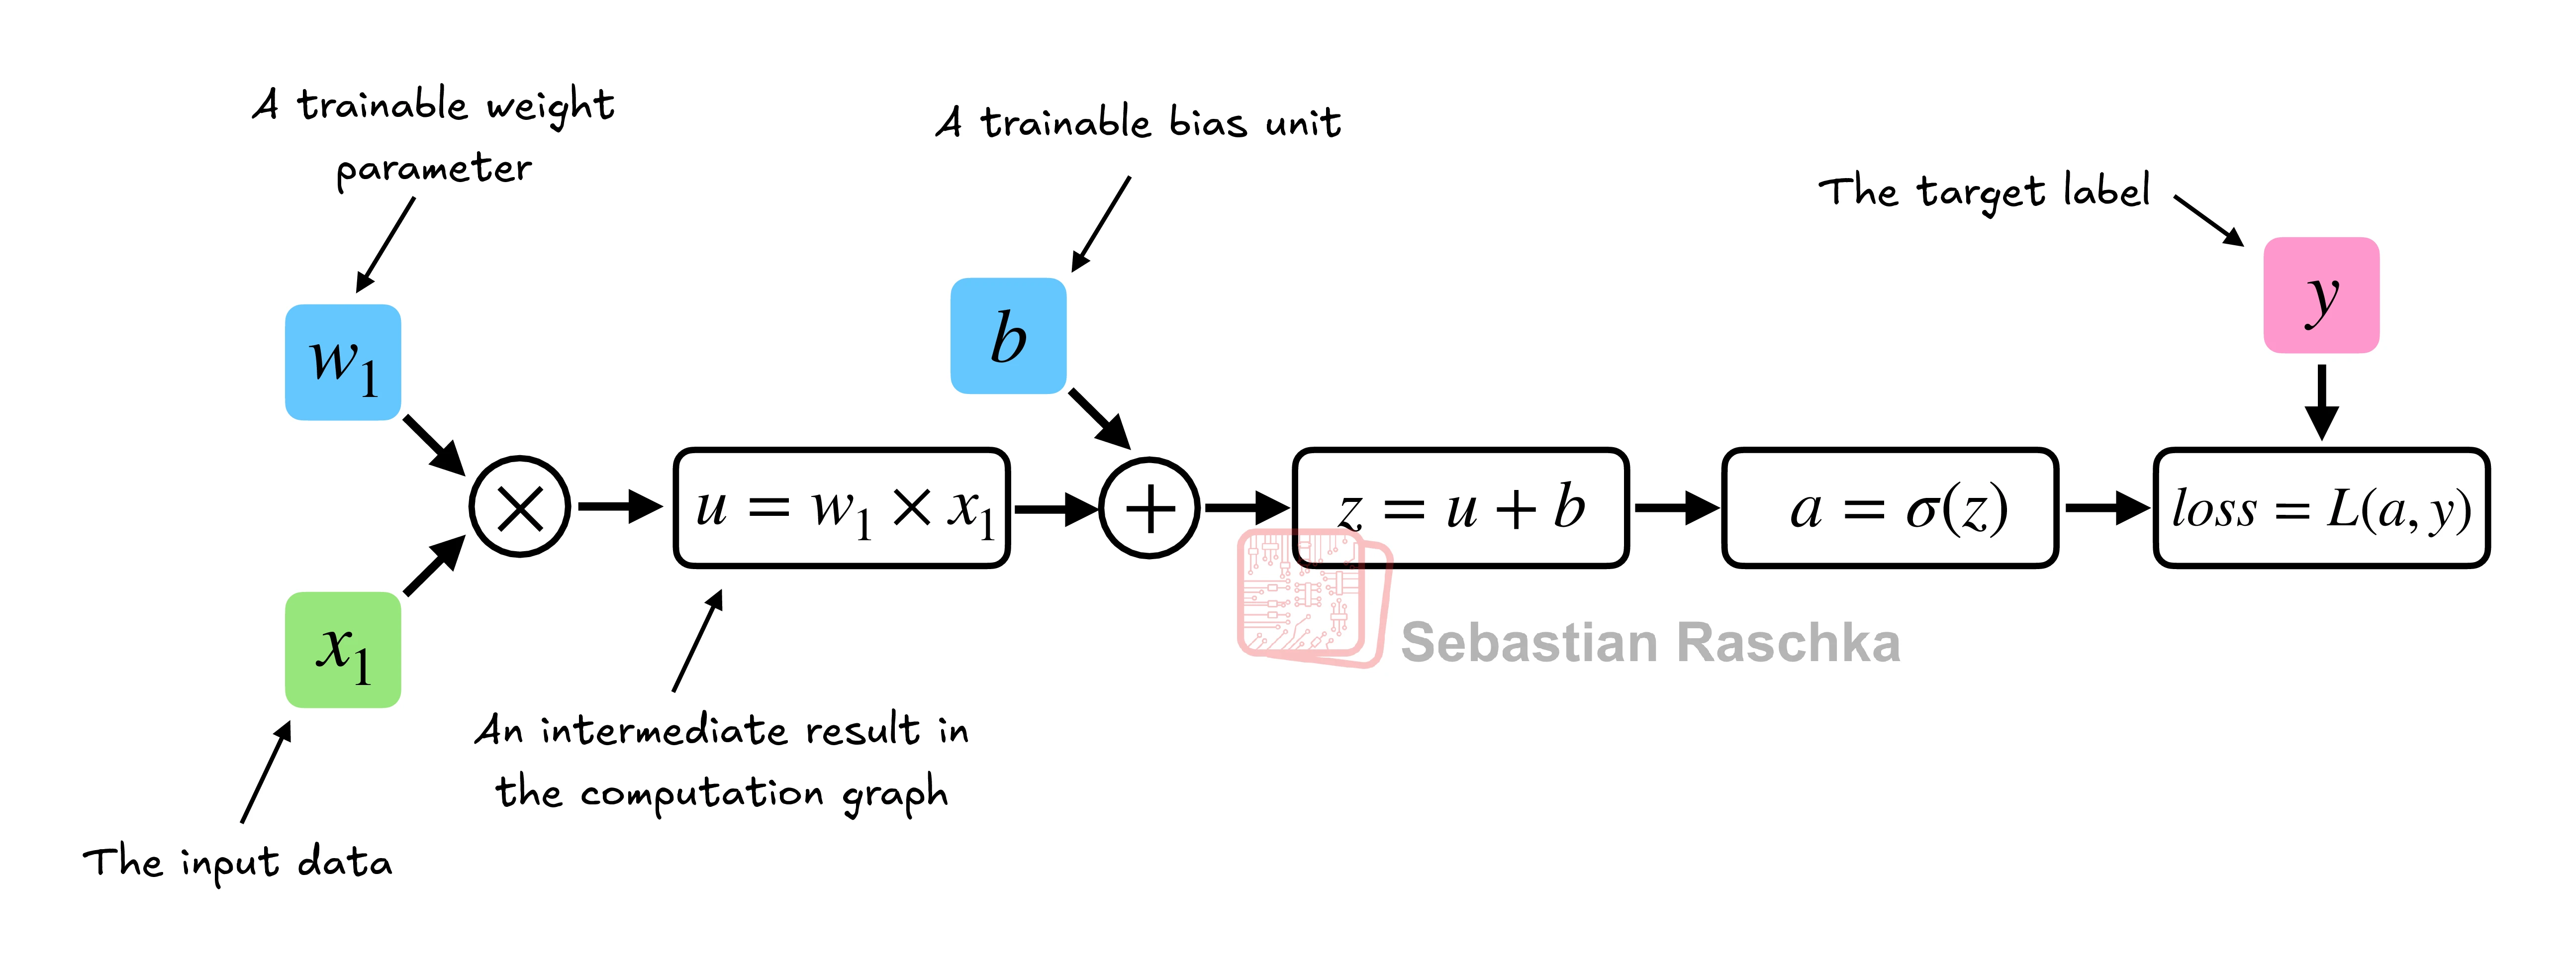





In [134]:
import torch.nn.functional as F

y = torch.tensor([1.0])  # true label
x1 = torch.tensor([1.1]) # input feature
w1 = torch.tensor([2.2]) # weight parameter
b = torch.tensor([0.0])  # bias unit

z = x1 * w1 + b          # net input
a = torch.sigmoid(z)     # activation & output

loss = F.binary_cross_entropy(a, y)
print(loss)

tensor(0.0852)


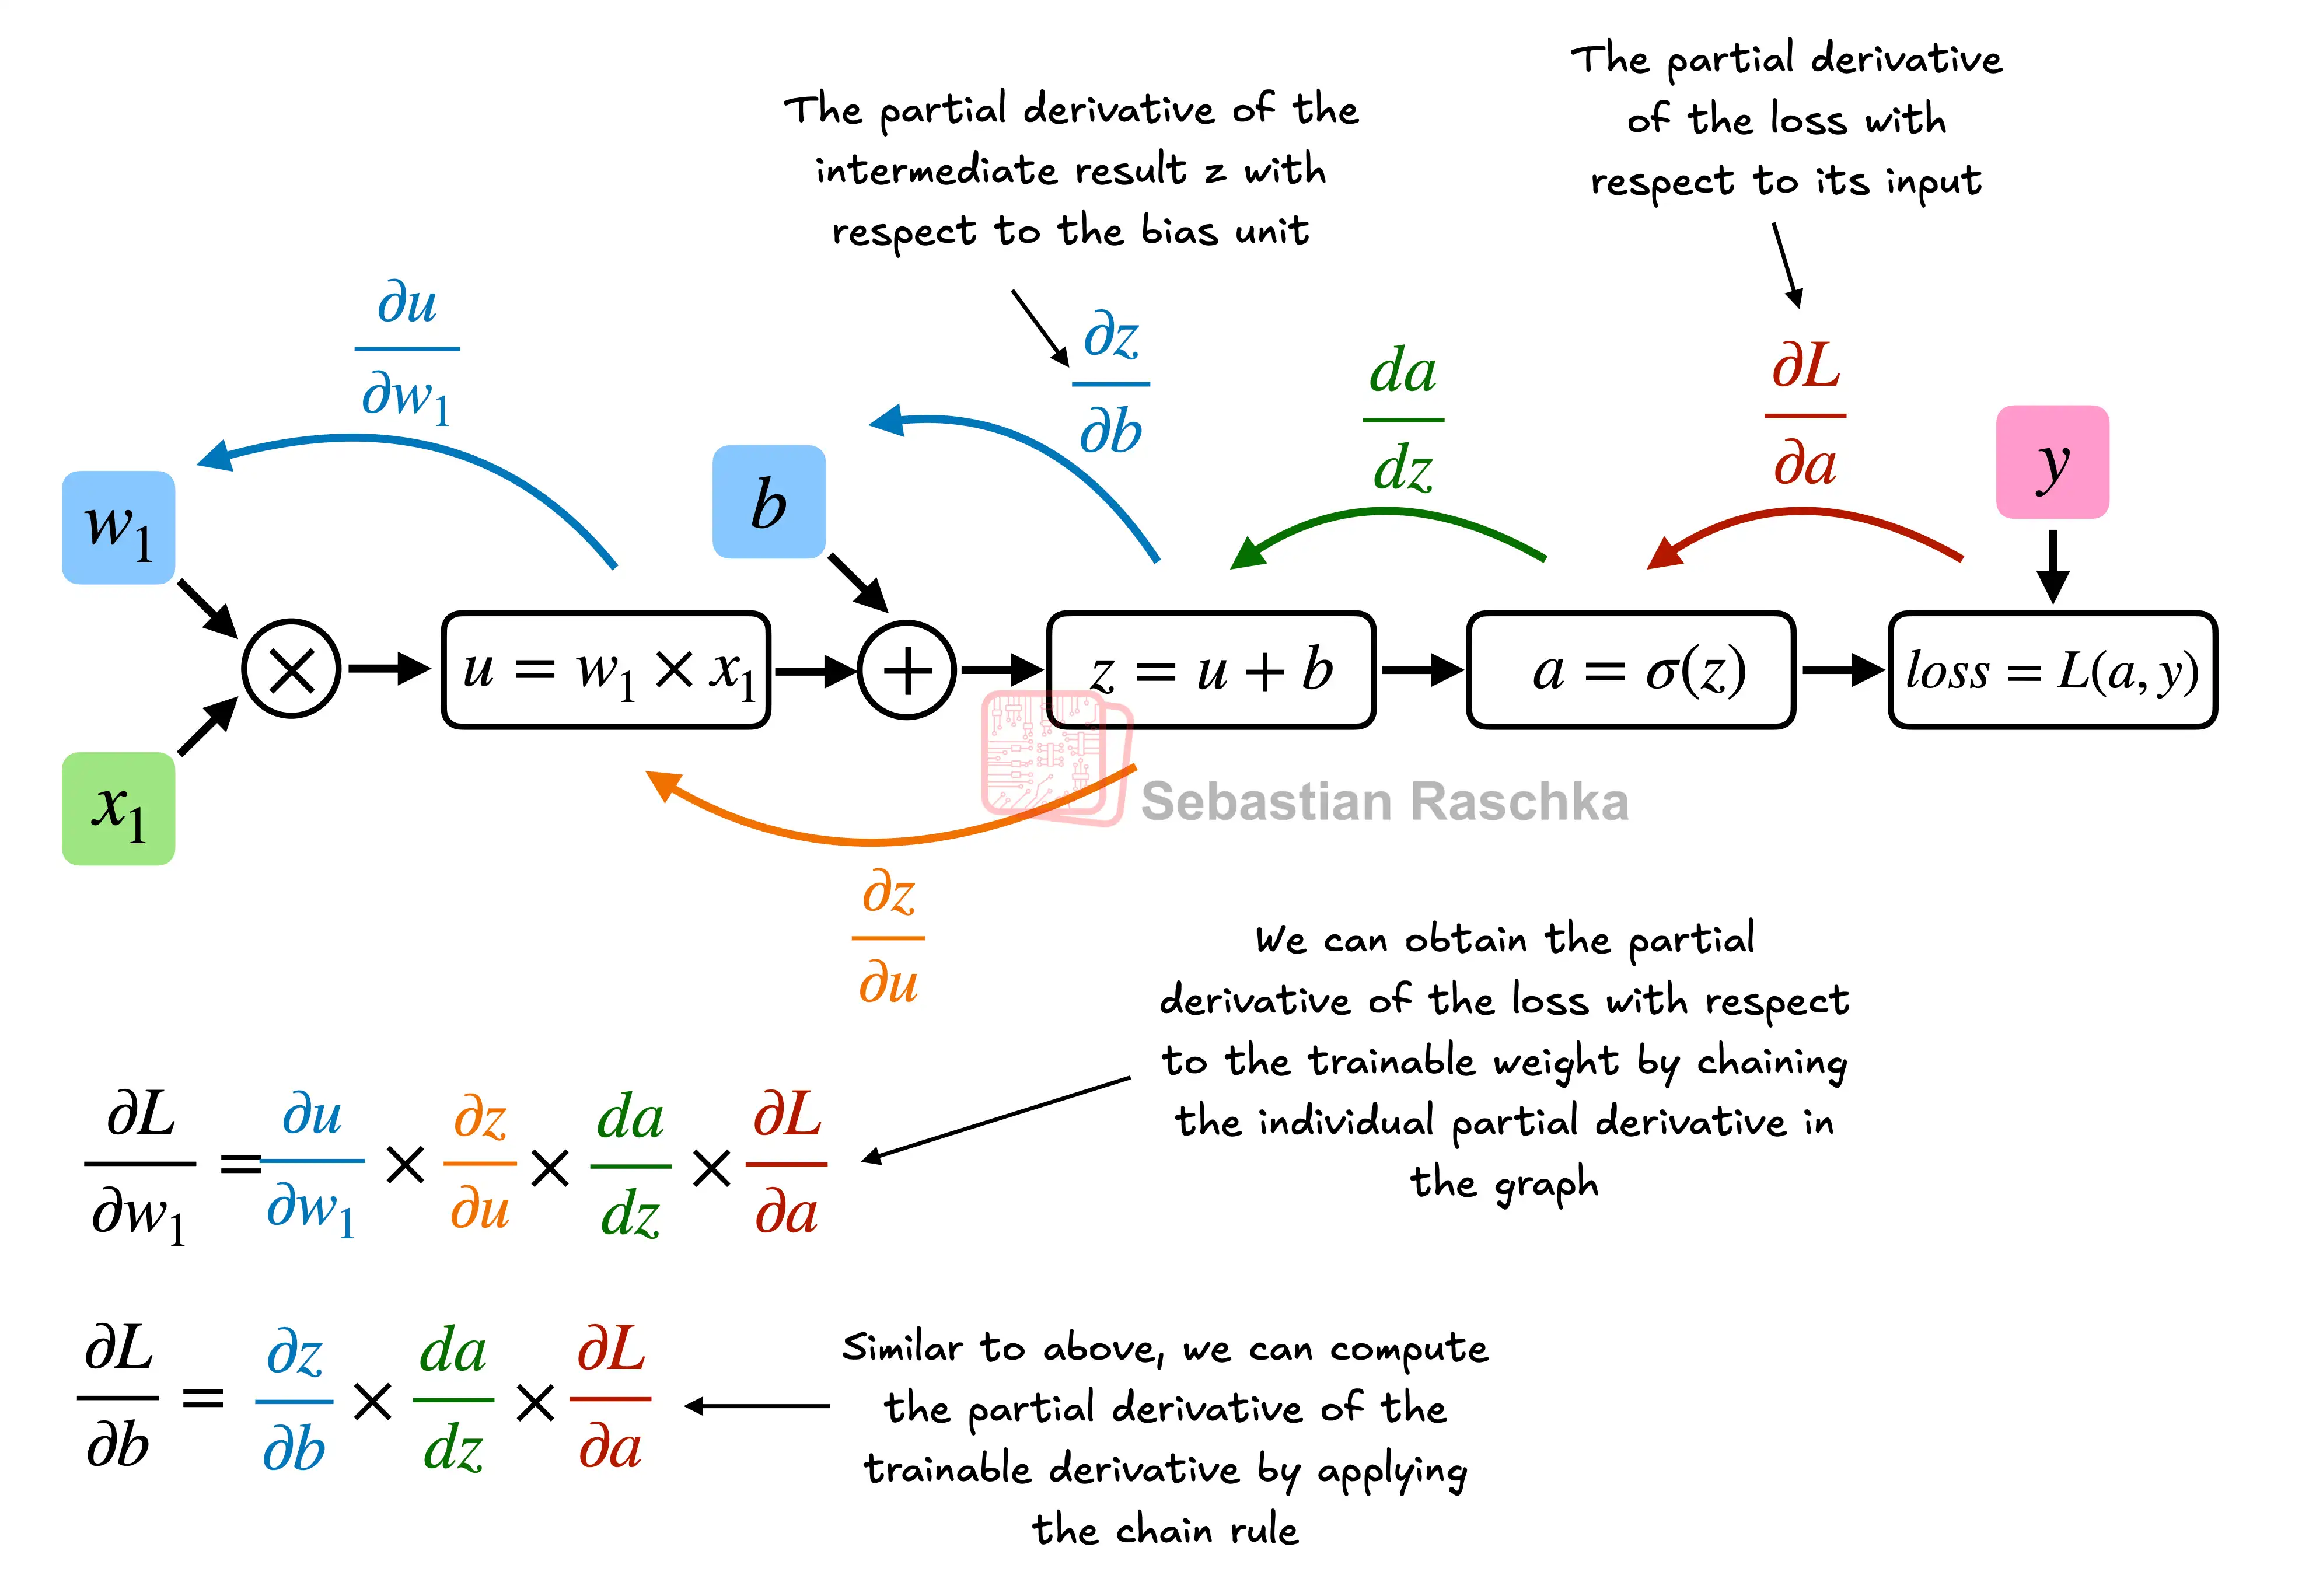

In [135]:
import torch.nn.functional as F
from torch.autograd import grad

y = torch.tensor([1.0])
x1 = torch.tensor([1.1])
w1 = torch.tensor([2.2], requires_grad=True)
b = torch.tensor([0.0], requires_grad=True)

z = x1 * w1 + b
a = torch.sigmoid(z)

loss = F.binary_cross_entropy(a, y)

grad_L_w1 = grad(loss, w1, retain_graph=True)   # default setting = True in PyTorch
grad_L_b = grad(loss, b, retain_graph=True)     # so that PyTorch doesn't destroy the graph

In [136]:
print(grad_L_w1)
print(grad_L_b)

(tensor([-0.0898]),)
(tensor([-0.0817]),)


In [137]:
loss.backward()

print(w1.grad)
print(b.grad)

tensor([-0.0898])
tensor([-0.0817])


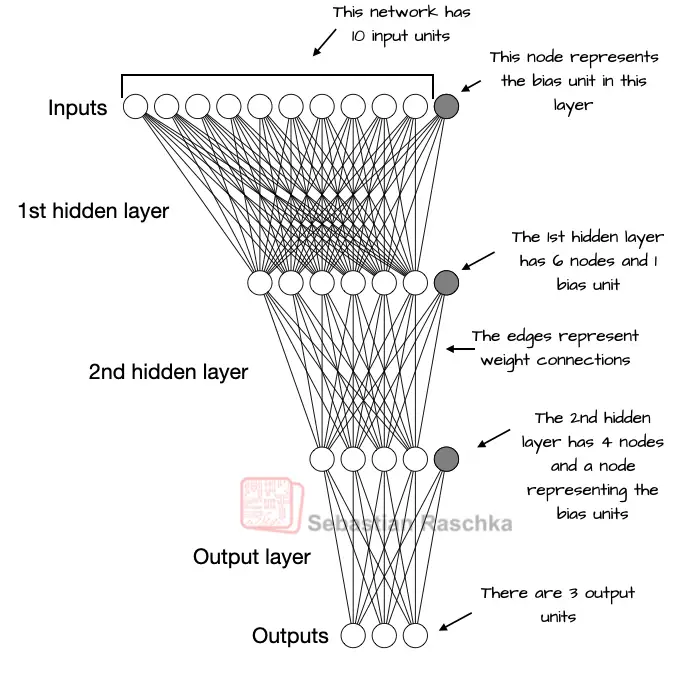

In [138]:
# this is a classic architecture already seen above :
class NeuralNetwork(torch.nn.Module):
    def __init__(self, num_inputs, num_outputs):
        super().__init__()

        self.layers = torch.nn.Sequential(

            # 1st hidden layer
            torch.nn.Linear(num_inputs, 30),
            torch.nn.ReLU(),

            # 2nd hidden layer
            torch.nn.Linear(30, 20),
            torch.nn.ReLU(),

            # output layer
            torch.nn.Linear(20, num_outputs),
        )

    def forward(self, x):
        logits = self.layers(x)
        return logits

In [139]:
model = NeuralNetwork(50, 3)

In [140]:
print(model)

NeuralNetwork(
  (layers): Sequential(
    (0): Linear(in_features=50, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=3, bias=True)
  )
)


In [141]:
num_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print("Total number of trainable model parameters:", num_params)

Total number of trainable model parameters: 2213


In [142]:
print(model.layers[0].weight)

Parameter containing:
tensor([[-0.0331,  0.1299, -0.0310,  ..., -0.0862, -0.1400, -0.0546],
        [-0.1085,  0.1160,  0.0407,  ..., -0.1368, -0.0810,  0.0353],
        [-0.0187, -0.1027,  0.0033,  ..., -0.1121,  0.0356, -0.0608],
        ...,
        [ 0.0515,  0.0091,  0.0993,  ..., -0.1175, -0.0444, -0.1318],
        [-0.0660,  0.0065, -0.0931,  ..., -0.0531,  0.0023, -0.1223],
        [ 0.0797,  0.1281,  0.0250,  ...,  0.1328,  0.1205, -0.0081]],
       requires_grad=True)


In [143]:
print(len(model.layers[0].weight))

30


In [148]:
print(model.layers[0].weight.shape)

torch.Size([30, 50])
